# ✈️  Regression Models for Predictive Maintenance
## Predicting Remaining Useful Life (RUL) of Aircraft Engines
### Dataset: NASA CMAPSS FD001 (Preprocessed)


**Problem Type:** Regression  
**Target Variable:** RUL (Remaining Useful Life)  
**Goal:** Train and compare multiple regression models, evaluate using MAE, MSE, RMSE, R² Score


## Import All Libraries

In [8]:
# Standard Libraries
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Preprocessing 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

# Regression Models
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline

# Evaluation Metrics 
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


## Load and Explore the Dataset

In [9]:

# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================

from pathlib import Path
import pandas as pd


# ============================================
# 2. DEFINE PROJECT AND DATASET PATHS
# ============================================

# Get the main project directory
PROJECT_DIR = Path.cwd().parent

# Path to the processed dataset
PROCESSED_DATA_PATH = (
    PROJECT_DIR / "data" / "processed" / "df_final_clean_FD001.csv"
)


# ============================================
# 3. CHECK DATASET AVAILABILITY
# ============================================

if not PROCESSED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Preprocessed dataset not found at: {PROCESSED_DATA_PATH}\n"
        "Please run the data preprocessing notebook first."
    )


# ============================================
# 4. LOAD PREPROCESSED DATASET
# ============================================

df = pd.read_csv(PROCESSED_DATA_PATH)


# ============================================
# 5. DISPLAY DATASET INFORMATION
# ============================================

print("=" * 50)
print("       PREPROCESSED FD001 DATASET")
print("=" * 50)

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


       PREPROCESSED FD001 DATASET

Dataset Shape:
(19599, 13)

Column Names:
['id', 'cycle', 'RUL', 'sensor4', 'sensor7', 'sensor8', 'sensor9', 'sensor11', 'sensor12', 'sensor13', 'sensor14', 'sensor15', 'sensor21']

First 5 Rows:


,id,cycle,RUL,sensor4,sensor7,sensor8,sensor9,sensor11,sensor12,sensor13,sensor14,sensor15,sensor21
0,1,1,191,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,23.4190
1,1,2,190,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,23.4236
2,1,3,189,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,23.3442
3,1,4,188,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,23.3739
4,1,5,187,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,23.4044



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19599 entries, 0 to 19598
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        19599 non-null  int64  
 1   cycle     19599 non-null  int64  
 2   RUL       19599 non-null  int64  
 3   sensor4   19599 non-null  float64
 4   sensor7   19599 non-null  float64
 5   sensor8   19599 non-null  float64
 6   sensor9   19599 non-null  float64
 7   sensor11  19599 non-null  float64
 8   sensor12  19599 non-null  float64
 9   sensor13  19599 non-null  float64
 10  sensor14  19599 non-null  float64
 11  sensor15  19599 non-null  float64
 12  sensor21  19599 non-null  float64
dtypes: float64(10), int64(3)
memory usage: 1.9 MB

Missing Values:
id          0
cycle       0
RUL         0
sensor4     0
sensor7     0
sensor8     0
sensor9     0
sensor11    0
sensor12    0
sensor13    0
sensor14    0
sensor15    0
sensor21    0
dtype: int64


In [10]:
# Basic statistical info
print("Dataset Info:")
df.info()

print("\n Statistical Summary:")
df.describe()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19599 entries, 0 to 19598
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        19599 non-null  int64  
 1   cycle     19599 non-null  int64  
 2   RUL       19599 non-null  int64  
 3   sensor4   19599 non-null  float64
 4   sensor7   19599 non-null  float64
 5   sensor8   19599 non-null  float64
 6   sensor9   19599 non-null  float64
 7   sensor11  19599 non-null  float64
 8   sensor12  19599 non-null  float64
 9   sensor13  19599 non-null  float64
 10  sensor14  19599 non-null  float64
 11  sensor15  19599 non-null  float64
 12  sensor21  19599 non-null  float64
dtypes: float64(10), int64(3)
memory usage: 1.9 MB

 Statistical Summary:


,id,cycle,RUL,sensor4,sensor7,sensor8,sensor9,sensor11,sensor12,sensor13,sensor14,sensor15,sensor21
count,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000,19599.000000
mean,51.661258,104.620185,112.225216,1408.116187,553.442370,2388.091459,9063.609974,47.517018,521.476092,2388.090850,8142.541865,8.438961,23.298668
std,29.207504,66.444156,66.531761,8.153774,0.810841,0.065176,17.609509,0.241817,0.673460,0.066014,15.259371,0.034428,0.099792
min,1.000000,1.000000,0.000000,1382.250000,550.430000,2387.900000,9023.850000,46.860000,519.060000,2387.880000,8106.140000,8.324900,22.912200
25%,26.000000,50.000000,58.000000,1402.160000,552.900000,2388.040000,9053.170000,47.340000,521.040000,2388.040000,8133.450000,8.414100,23.233850
50%,53.000000,99.000000,107.000000,1407.540000,553.490000,2388.090000,9060.520000,47.500000,521.520000,2388.090000,8140.440000,8.436900,23.303300
75%,77.000000,150.000000,157.000000,1413.480000,554.030000,2388.130000,9068.780000,47.670000,521.970000,2388.130000,8147.770000,8.461650,23.369700
max,100.000000,355.000000,361.000000,1437.070000,556.060000,2388.330000,9193.090000,48.330000,523.380000,2388.330000,8256.400000,8.567800,23.612700


In [4]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing:", df.isnull().sum().sum())

Missing Values:
id          0
cycle       0
RUL         0
sensor4     0
sensor7     0
sensor8     0
sensor9     0
sensor11    0
sensor12    0
sensor13    0
sensor14    0
sensor15    0
sensor21    0
dtype: int64

Total Missing: 0


## Prepare Features (X) and Target (y)

In [5]:
# Split into Features and Target
# 'RUL' is our target variable (what we want to predict)
# All other columns are features (means input to the model)

X = df.drop(columns=['RUL'])   # Features
y = df['RUL']                  # Target

print("Features (X) shape:", X.shape)
print("Target  (y) shape:", y.shape)
print("\nFeature columns:", X.columns.tolist())

print("\nTarget variable: RUL")
print(f"   Min RUL: {y.min():.4f}")
print(f"   Max RUL: {y.max():.4f}")
print(f"   Mean RUL: {y.mean():.4f}")

Features (X) shape: (19599, 12)
Target  (y) shape: (19599,)

Feature columns: ['id', 'cycle', 'sensor4', 'sensor7', 'sensor8', 'sensor9', 'sensor11', 'sensor12', 'sensor13', 'sensor14', 'sensor15', 'sensor21']

Target variable: RUL
   Min RUL: 0.0000
   Max RUL: 361.0000
   Mean RUL: 112.2252


In [6]:
# Train-Test Split 
# 80% for training, 20% for testing
# random_state=42 ensures reproducibility (same split every run)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Data Split Summary:")
print(f"   Training samples  : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   Testing  samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"   Number of features: {X_train.shape[1]}")

Data Split Summary:
   Training samples  : 15679 (80.0%)
   Testing  samples  : 3920  (20.0%)
   Number of features: 12


In [7]:
# Feature Scaling
# StandardScaler: transforms data to have mean=0, std=1
# IMPORTANT: Fit only on training data, then transform both train and test
# (to avoid data leakage from test set into the scaler)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + Transform on train
X_test_scaled  = scaler.transform(X_test)        # Only Transform on test

print("Feature scaling complete (StandardScaler applied)")
print(f"   Train mean (should be ~0): {X_train_scaled.mean():.6f}")
print(f"   Train std  (should be ~1): {X_train_scaled.std():.6f}")

Feature scaling complete (StandardScaler applied)
   Train mean (should be ~0): 0.000000
   Train std  (should be ~1): 1.000000


## Define Evaluation Helper Function

We create a helper function to evaluate every model using 4 metrics:
- **MAE** → Mean Absolute Error (lower = better)
- **MSE** → Mean Squared Error (lower = better)  
- **RMSE** → Root Mean Squared Error (lower = better)
- **R²** → R-squared Score (higher = better, max=1.0)

In [8]:
results = {}

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    """
    Train a model and evaluate it using MAE, MSE, RMSE, R² Score.
    Stores results in the global 'results' dictionary.
    """
    # Train the model
    model.fit(X_tr, y_tr)
    
    # Predict on test set
    y_pred = model.predict(X_te)
    
    # Calculate metrics
    mae  = mean_absolute_error(y_te, y_pred)
    mse  = mean_squared_error(y_te, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_te, y_pred)
    
    # Store results
    results[name] = {
        'MAE' : round(mae,  5),
        'MSE' : round(mse,  5),
        'RMSE': round(rmse, 5),
        'R2'  : round(r2,   5)
    }
    
    # Print formatted output
    print(f"\n{'='*50}")
    print(f"  Model : {name}")
    print(f"{'='*50}")
    print(f"  MAE   : {mae:.5f}")
    print(f"  MSE   : {mse:.5f}")
    print(f"  RMSE  : {rmse:.5f}")
    print(f"  R²    : {r2:.5f}")
    print(f"{'='*50}")
    
    return y_pred

print("Evaluation function defined!")

Evaluation function defined!


---
##  Required Regression Models
---

### Model 1 — Simple Linear Regression

**What it does:** Fits a straight line between ONE feature and the target.  
**Formula:** `y = mx + b`  
**Used here:** We use the single most correlated feature with RUL.

In [9]:
# Simple Linear Regression (uses 1 feature only) 
# Find the feature most correlated with RUL
correlations = abs(df.corr()['RUL'].drop('RUL'))
best_feature = correlations.idxmax()
print(f"Most correlated feature with RUL: '{best_feature}' (corr = {correlations.max():.4f})")

# Use only that single feature
X_train_slr = X_train_scaled[:, X.columns.get_loc(best_feature)].reshape(-1, 1)
X_test_slr  = X_test_scaled[:,  X.columns.get_loc(best_feature)].reshape(-1, 1)

slr = LinearRegression()
y_pred_slr = evaluate_model(
    'Simple Linear Regression',
    slr, X_train_slr, y_train, X_test_slr, y_test
)

Most correlated feature with RUL: 'cycle' (corr = 0.7150)

  Model : Simple Linear Regression
  MAE   : 35.56237
  MSE   : 2102.55761
  RMSE  : 45.85365
  R²    : 0.50744


### Model 2 — Multiple Linear Regression

**What it does:** Fits a linear equation using ALL features simultaneously.  
**Formula:** `y = b0 + b1*x1 + b2*x2 + ... + bn*xn`  
**Advantage over Simple LR:** Uses all sensor data, not just one.

In [10]:
# ── Multiple Linear Regression (uses ALL features) ───────────────────────────
mlr = LinearRegression()
y_pred_mlr = evaluate_model(
    'Multiple Linear Regression',
    mlr, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Multiple Linear Regression
  MAE   : 30.55594
  MSE   : 1563.01715
  RMSE  : 39.53501
  R²    : 0.63383


### Model 3 — Polynomial Regression

**What it does:** Extends linear regression by adding polynomial (curved) terms.  
**Formula:** `y = b0 + b1*x + b2*x² + ...`  
**Degree=2** means we add squared terms — can capture non-linear relationships.

In [11]:
# ── Polynomial Regression (degree = 2) ───────────────────────────────────────
# We use Pipeline to chain PolynomialFeatures + LinearRegression together
# This is cleaner than doing it manually in two steps

poly_reg = Pipeline([
    ('poly',  PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression())
])

y_pred_poly = evaluate_model(
    'Polynomial Regression (deg=2)',
    poly_reg, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Polynomial Regression (deg=2)
  MAE   : 26.25642
  MSE   : 1292.07509
  RMSE  : 35.94545
  R²    : 0.69731


### Model 4 — Support Vector Regression (SVR)

**What it does:** Finds a function that fits within a margin (epsilon) of error.  
**Key idea:** Instead of minimizing error directly, it allows a tolerance band.  
**kernel='rbf'** → Radial Basis Function — works well with non-linear data.

In [12]:
# Support Vector Regression (SVR)
# C      : Regularization (higher = less regularization)
# epsilon: Tolerance margin (predictions within this margin have no penalty)
# kernel : 'rbf' is the most popular for non-linear data

svr = SVR(kernel='rbf', C=100, epsilon=0.00001)
y_pred_svr = evaluate_model(
    'Support Vector Regression (SVR)',
    svr, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Support Vector Regression (SVR)
  MAE   : 23.21106
  MSE   : 1166.92935
  RMSE  : 34.16035
  R²    : 0.72662


---
##  Additional Regression Models
---

### Model 5 — Decision Tree Regression

**What it does:** Splits data into branches based on feature thresholds.  
**Advantage:** Easy to visualize and interpret.  
**Disadvantage:** Can overfit if tree is too deep.

In [13]:
# Decision Tree Regression
# max_depth: Limits tree depth to prevent overfitting
# min_samples_leaf: Minimum samples required at a leaf node

dt = DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42)
y_pred_dt = evaluate_model(
    'Decision Tree Regression',
    dt, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Decision Tree Regression
  MAE   : 18.70611
  MSE   : 727.24471
  RMSE  : 26.96747
  R²    : 0.82963


### Model 66 — Random Forest Regression

**What it does:** Builds many decision trees and averages their predictions.  
**Advantage:** More robust than a single decision tree, reduces overfitting.  
**n_estimators:** Number of trees in the forest.

In [14]:
# Random Forest Regression
# n_estimators: Number of trees (more = better but slower)
# max_depth   : Limit tree depth to avoid overfitting

rf = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
y_pred_rf = evaluate_model(
    'Random Forest Regression',
    rf, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Random Forest Regression
  MAE   : 12.84927
  MSE   : 300.17102
  RMSE  : 17.32544
  R²    : 0.92968


### Model 7 — Ridge Regression

**What it does:** Linear regression with L2 regularization (penalizes large coefficients).  
**Solves:** Overfitting in Multiple Linear Regression.  
**alpha:** Controls how much regularization — higher alpha = more penalty.

In [15]:
# Ridge Regression (L2 Regularization)
ridge = Ridge(alpha=1.0)
y_pred_ridge = evaluate_model(
    'Ridge Regression',
    ridge, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Ridge Regression
  MAE   : 30.55581
  MSE   : 1563.01243
  RMSE  : 39.53495
  R²    : 0.63383


### Model 8 — Lasso Regression

**What it does:** Linear regression with L1 regularization.  
**Special feature:** Can shrink some coefficients to exactly ZERO (automatic feature selection!).  
**Difference from Ridge:** Ridge keeps all features, Lasso can eliminate them.

In [16]:
# Lasso Regression (L1 Regularization)
lasso = Lasso(alpha=0.0000001, max_iter=10000)
y_pred_lasso = evaluate_model(
    'Lasso Regression',
    lasso, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Lasso Regression
  MAE   : 30.55594
  MSE   : 1563.01715
  RMSE  : 39.53501
  R²    : 0.63383


### Model 9 — Elastic Net Regression

**What it does:** Combines BOTH L1 (Lasso) and L2 (Ridge) regularization.  
**l1_ratio:** Controls the mix — 0 = pure Ridge, 1 = pure Lasso, 0.5 = equal mix.  
**Best for:** When there are many features and some are correlated.

In [17]:
# Elastic Net Regression (L1 + L2) 
enet = ElasticNet(alpha=0.0000001, l1_ratio=0.5, max_iter=10000)
y_pred_enet = evaluate_model(
    'Elastic Net Regression',
    enet, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Elastic Net Regression
  MAE   : 30.55594
  MSE   : 1563.01714
  RMSE  : 39.53501
  R²    : 0.63383


### Model 10 — Gradient Boosting Regression

**What it does:** Builds trees sequentially — each new tree corrects errors of the previous.  
**Advantage:** Usually one of the best-performing ML models.  
**learning_rate:** How much each tree contributes (small = better, but needs more trees).

In [18]:
# Gradient Boosting Regression 
# n_estimators  : Number of boosting stages (trees)
# learning_rate : Shrinks contribution of each tree (smaller = more robust)
# max_depth     : Depth of each individual tree

gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
y_pred_gb = evaluate_model(
    'Gradient Boosting Regression',
    gb, X_train_scaled, y_train, X_test_scaled, y_test
)


  Model : Gradient Boosting Regression
  MAE   : 10.67251
  MSE   : 190.85204
  RMSE  : 13.81492
  R²    : 0.95529



##  Compare All Models

Now we compile all results into a single table for easy comparison.

In [19]:
# Build Comparison DataFrame

results_df = pd.DataFrame(results).T.reset_index()
results_df.columns = ['Model', 'MAE', 'MSE', 'RMSE', 'R2 Score']

# Sort by R² Score (descending) — best model at top
results_df = results_df.sort_values('R2 Score', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1  # Start rank from 1

print("\n" + "="*80)
print("          ALL MODELS PERFORMANCE COMPARISON (Sorted by R² Score)")
print("="*80)
print(results_df.to_string())
print("="*80)
print(f"\n Best Model  : {results_df.iloc[0]['Model']}")
print(f"   R² Score    : {results_df.iloc[0]['R2 Score']}")
print(f"   RMSE        : {results_df.iloc[0]['RMSE']}")
print(f"\nHigher R² = Better | Lower MAE/MSE/RMSE = Better")


          ALL MODELS PERFORMANCE COMPARISON (Sorted by R² Score)
                              Model       MAE         MSE      RMSE  R2 Score
1      Gradient Boosting Regression  10.67251   190.85204  13.81492   0.95529
2          Random Forest Regression  12.84927   300.17102  17.32544   0.92968
3          Decision Tree Regression  18.70611   727.24471  26.96747   0.82963
4   Support Vector Regression (SVR)  23.21106  1166.92935  34.16035   0.72662
5     Polynomial Regression (deg=2)  26.25642  1292.07509  35.94545   0.69731
6        Multiple Linear Regression  30.55594  1563.01715  39.53501   0.63383
7                  Lasso Regression  30.55594  1563.01715  39.53501   0.63383
8                  Ridge Regression  30.55581  1563.01243  39.53495   0.63383
9            Elastic Net Regression  30.55594  1563.01714  39.53501   0.63383
10         Simple Linear Regression  35.56237  2102.55761  45.85365   0.50744

 Best Model  : Gradient Boosting Regression
   R² Score    : 0.95529
   RMS

---
## Step 6 — Visualizations

### Plot 1 — R² Score Comparison (Bar Chart)

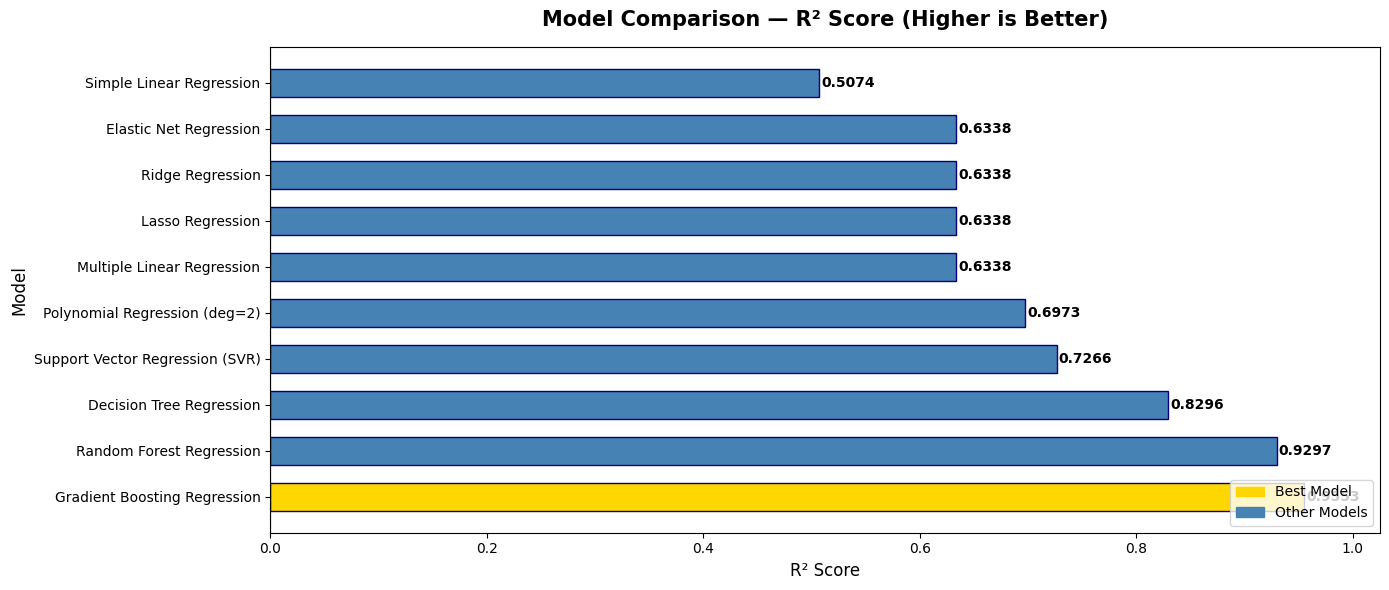

✅ Plot 1 saved!


In [20]:
# Plot 1: R² Score Bar Chart 
fig, ax = plt.subplots(figsize=(14, 6))

# Color bars: best model = gold, rest = steelblue
colors = ['gold' if i == 0 else 'steelblue' for i in range(len(results_df))]

bars = ax.barh(results_df['Model'], results_df['R2 Score'], color=colors, edgecolor='navy', height=0.6)

# Add value labels inside/outside bars
for bar, val in zip(bars, results_df['R2 Score']):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10, fontweight='bold')

ax.set_title('Model Comparison — R² Score (Higher is Better)', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('R² Score', fontsize=12)
ax.set_ylabel('Model', fontsize=12)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlim(left=min(0, results_df['R2 Score'].min() - 0.05),
            right=results_df['R2 Score'].max() + 0.07)

gold_patch = mpatches.Patch(color='gold', label='Best Model')
blue_patch = mpatches.Patch(color='steelblue', label='Other Models')
ax.legend(handles=[gold_patch, blue_patch], loc='lower right')

plt.tight_layout()
plt.savefig('plot1_r2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot 1 saved!")

### Plot 2 — Error Metrics Comparison (MAE, RMSE)

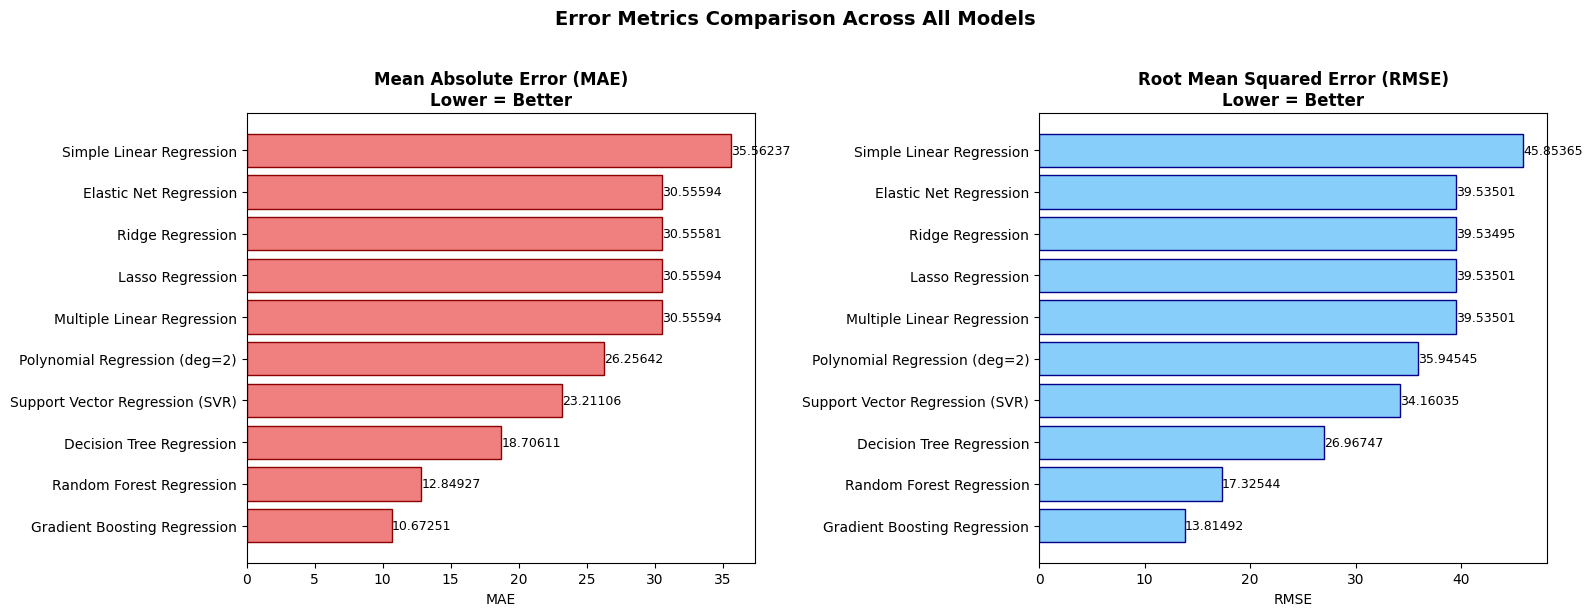

✅ Plot 2 saved!


In [21]:
# ─── Plot 2: MAE and RMSE Side-by-Side ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models_sorted = results_df['Model'].tolist()

# --- MAE ---
colors_mae = ['tomato' if i == results_df['MAE'].idxmin()-1 else 'lightcoral'
              for i in range(len(results_df))]
axes[0].barh(models_sorted, results_df['MAE'], color='lightcoral', edgecolor='darkred')
for i, v in enumerate(results_df['MAE']):
    axes[0].text(v + 0.0001, i, f'{v:.5f}', va='center', fontsize=9)
axes[0].set_title('Mean Absolute Error (MAE)\nLower = Better', fontsize=12, fontweight='bold')
axes[0].set_xlabel('MAE')

# --- RMSE ---
axes[1].barh(models_sorted, results_df['RMSE'], color='lightskyblue', edgecolor='darkblue')
for i, v in enumerate(results_df['RMSE']):
    axes[1].text(v + 0.0001, i, f'{v:.5f}', va='center', fontsize=9)
axes[1].set_title('Root Mean Squared Error (RMSE)\nLower = Better', fontsize=12, fontweight='bold')
axes[1].set_xlabel('RMSE')

plt.suptitle('Error Metrics Comparison Across All Models', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plot2_error_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot 2 saved!")

### Plot 3 — All Metrics Heatmap

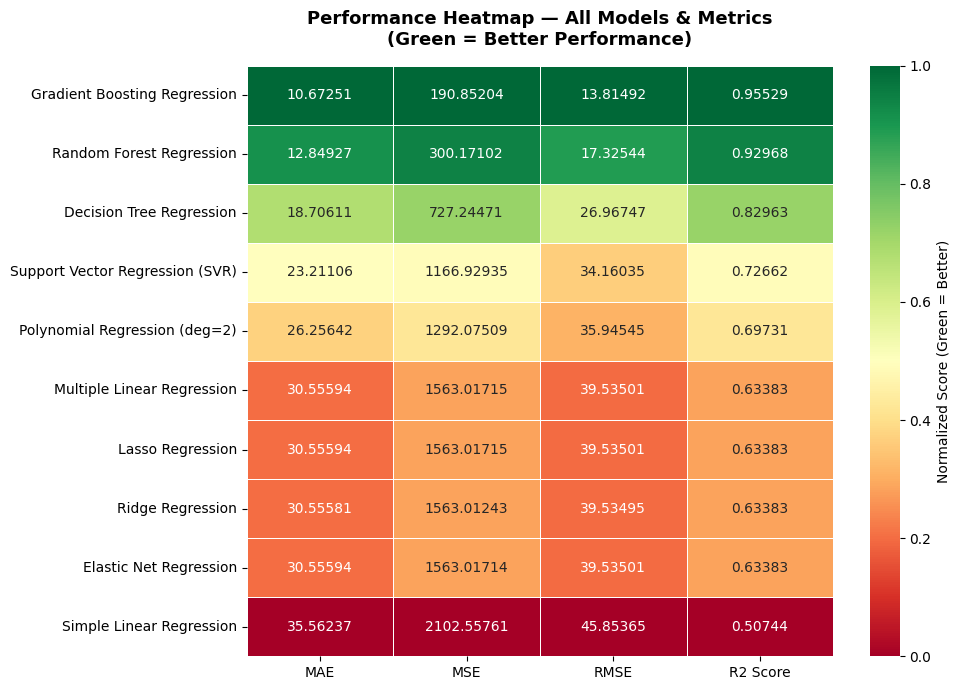

✅ Plot 3 saved!


In [22]:
# ─── Plot 3: Heatmap of all metrics ───────────────────────────────────────────
heatmap_data = results_df.set_index('Model')[['MAE', 'MSE', 'RMSE', 'R2 Score']]

# Normalize each column to 0-1 for fair heatmap color comparison
heatmap_norm = heatmap_data.copy()
for col in ['MAE', 'MSE', 'RMSE']:
    heatmap_norm[col] = 1 - (heatmap_data[col] - heatmap_data[col].min()) / \
                            (heatmap_data[col].max() - heatmap_data[col].min() + 1e-10)
# R2 already: higher = better, normalize directly
heatmap_norm['R2 Score'] = (heatmap_data['R2 Score'] - heatmap_data['R2 Score'].min()) / \
                            (heatmap_data['R2 Score'].max() - heatmap_data['R2 Score'].min() + 1e-10)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    heatmap_norm,
    annot=heatmap_data.round(5),   # Show original values
    fmt='.5f',
    cmap='RdYlGn',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Normalized Score (Green = Better)'}
)
ax.set_title('Performance Heatmap — All Models & Metrics\n(Green = Better Performance)', 
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('plot3_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot 3 saved!")

### Plot 4 — Actual vs Predicted (Best Model)

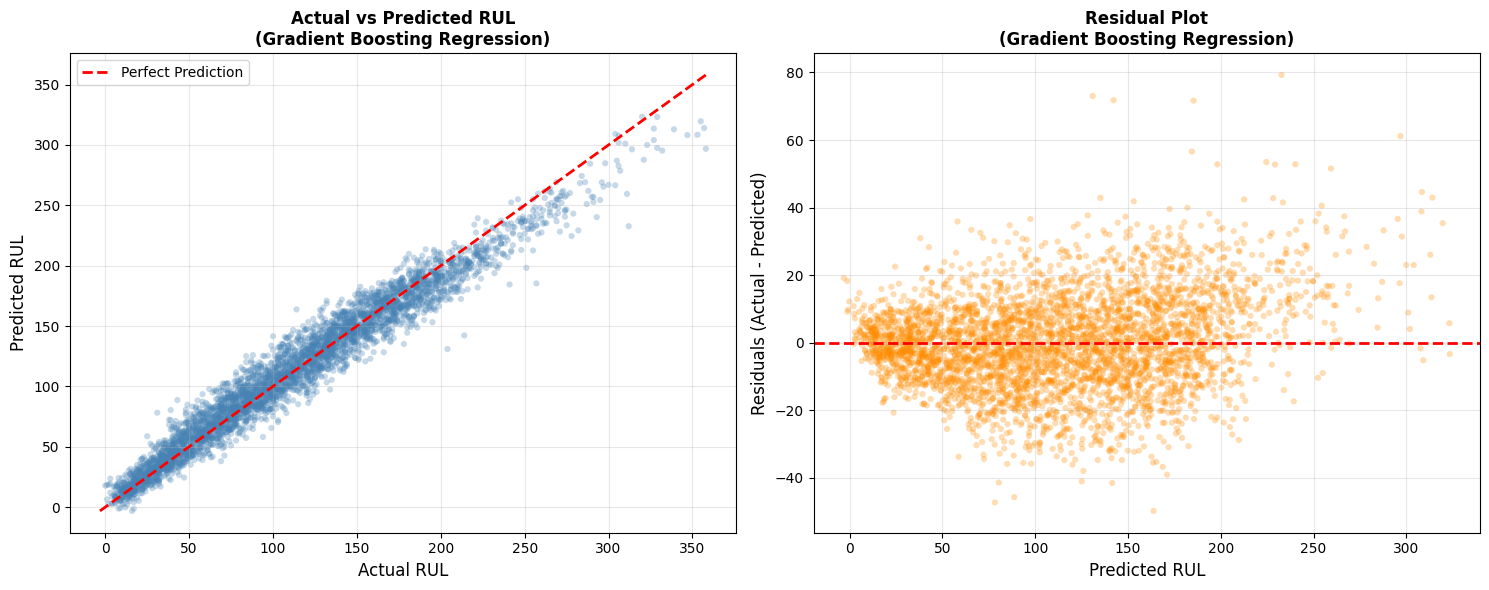

✅ Plot 4 saved!


In [23]:
# ─── Plot 4: Actual vs Predicted for Best Model ───────────────────────────────
# Find which model is best and re-predict
best_model_name = results_df.iloc[0]['Model']

# Map name to prediction array
pred_map = {
    'Simple Linear Regression'           : y_pred_slr,
    'Multiple Linear Regression'         : y_pred_mlr,
    'Polynomial Regression (deg=2)'      : y_pred_poly,
    'Support Vector Regression (SVR)'    : y_pred_svr,
    'Decision Tree Regression'           : y_pred_dt,
    'Random Forest Regression'           : y_pred_rf,
    'Ridge Regression'                   : y_pred_ridge,
    'Lasso Regression'                   : y_pred_lasso,
    'Elastic Net Regression'             : y_pred_enet,
    'Gradient Boosting Regression'       : y_pred_gb
}

best_pred = pred_map[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scatter: Actual vs Predicted
axes[0].scatter(y_test, best_pred, alpha=0.3, color='steelblue', edgecolors='none', s=20)
min_val = min(y_test.min(), best_pred.min())
max_val = max(y_test.max(), best_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual RUL', fontsize=12)
axes[0].set_ylabel('Predicted RUL', fontsize=12)
axes[0].set_title(f'Actual vs Predicted RUL\n({best_model_name})', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Residuals plot
residuals = y_test.values - best_pred
axes[1].scatter(best_pred, residuals, alpha=0.3, color='darkorange', edgecolors='none', s=20)
axes[1].axhline(y=0, color='red', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted RUL', fontsize=12)
axes[1].set_ylabel('Residuals (Actual - Predicted)', fontsize=12)
axes[1].set_title(f'Residual Plot\n({best_model_name})', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('plot4_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot 4 saved!")

### Plot 5 — Feature Importance (Random Forest)

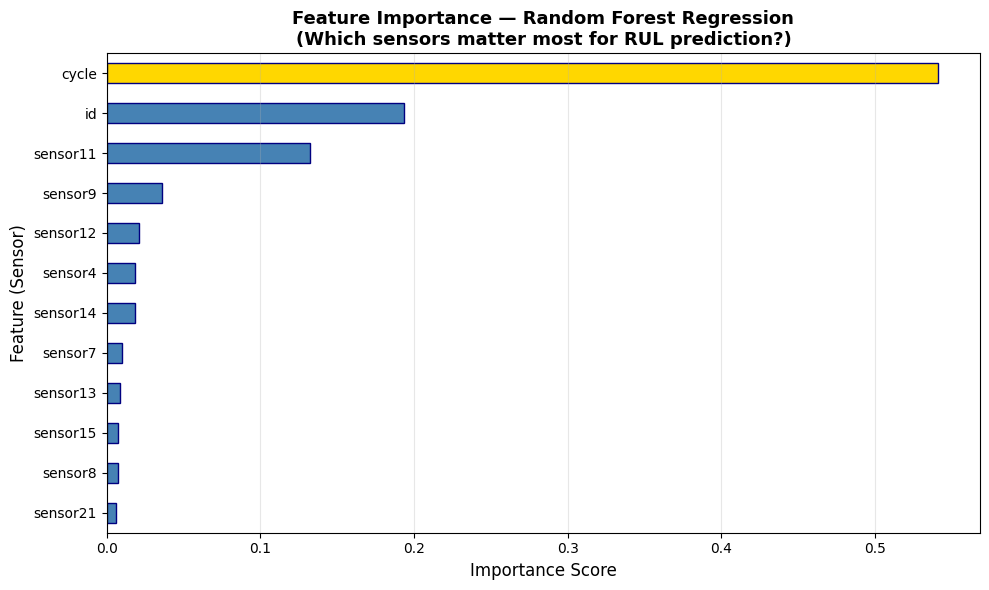

✅ Plot 5 saved!


In [24]:
# ─── Plot 5: Feature Importance from Random Forest ───────────────────────────
# Random Forest gives us feature importance scores automatically
importance = pd.Series(rf.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors_feat = ['gold' if imp == importance.max() else 'steelblue' for imp in importance]
importance.plot(kind='barh', ax=ax, color=colors_feat, edgecolor='navy')
ax.set_title('Feature Importance — Random Forest Regression\n(Which sensors matter most for RUL prediction?)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Importance Score', fontsize=12)
ax.set_ylabel('Feature (Sensor)', fontsize=12)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('plot5_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot 5 saved!")

### Plot 6 — Line Graph: All Metrics Side by Side

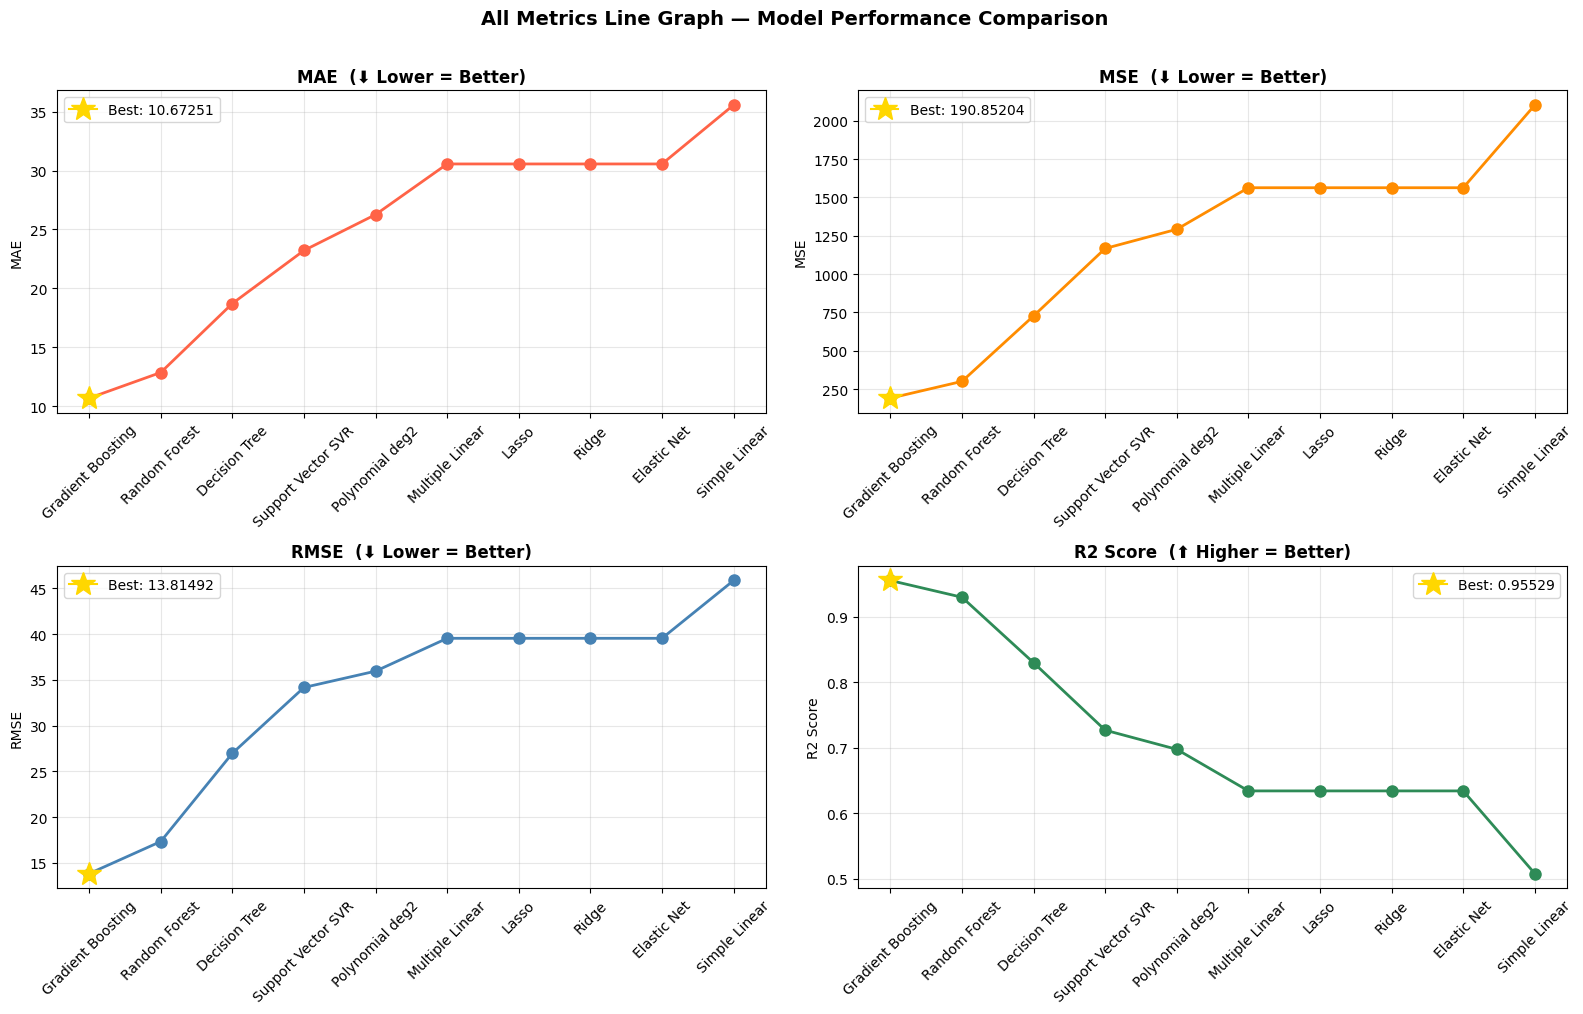

✅ Plot 6 saved!


In [25]:
# ─── Plot 6: Line graph comparison of all models ─────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

metrics = ['MAE', 'MSE', 'RMSE', 'R2 Score']
colors_line = ['tomato', 'darkorange', 'steelblue', 'seagreen']
best_is_low = [True, True, True, False]  # For MAE/MSE/RMSE lower=better, R2 higher=better

model_names_short = [
    m.replace(' Regression', '').replace('(', '').replace(')', '').replace('deg=2', 'deg2')
    for m in results_df['Model']
]

for ax, metric, color, low_best in zip(axes.flatten(), metrics, colors_line, best_is_low):
    values = results_df[metric].values
    ax.plot(model_names_short, values, marker='o', color=color, linewidth=2, markersize=8)
    
    # Highlight best value
    best_idx = values.argmin() if low_best else values.argmax()
    ax.plot(model_names_short[best_idx], values[best_idx], 
            marker='*', color='gold', markersize=18, zorder=5, label=f'Best: {values[best_idx]:.5f}')
    
    direction = '⬇ Lower = Better' if low_best else '⬆ Higher = Better'
    ax.set_title(f'{metric}  ({direction})', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle('All Metrics Line Graph — Model Performance Comparison', 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('plot6_line_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot 6 saved!")

---
## Final Summary & Conclusion

In [26]:
# ─── Final Summary Table ──────────────────────────────────────────────────────

print(f"\n{'Rank':<5} {'Model':<40} {'MAE':>8} {'MSE':>10} {'RMSE':>8} {'R²':>8}")
print("-"*85)
for rank, row in results_df.iterrows():
    medal = '1' if rank == 1 else '2' if rank == 2 else '3' if rank == 3 else f'  {rank} '
    print(f"{medal}  {row['Model']:<40} {row['MAE']:>8.5f} {row['MSE']:>10.5f} {row['RMSE']:>8.5f} {row['R2 Score']:>8.5f}")
print("="*85)

best = results_df.iloc[0]
print(f"\n BEST MODEL : {best['Model']}")
print(f"   R² Score   : {best['R2 Score']} (explains {best['R2 Score']*100:.2f}% of variance in RUL)")
print(f"   RMSE       : {best['RMSE']}")
print(f"   MAE        : {best['MAE']}")

print("\n" + "="*85)
print("  EXPLANATION OF METRICS")
print("="*85)
print("  MAE   = Average absolute difference between actual and predicted RUL")
print("  MSE   = Average squared difference (penalizes large errors more)")
print("  RMSE  = Square root of MSE (same unit as RUL, easier to interpret)")
print("  R²    = Proportion of variance explained by the model (1.0 = perfect)")
print("="*85)
print("\n  For lower R² values: Note that RUL is normalized (0-1 scale).")
print("  Small absolute errors (MAE/RMSE) still indicate good predictions.")


Rank  Model                                         MAE        MSE     RMSE       R²
-------------------------------------------------------------------------------------
1  Gradient Boosting Regression             10.67251  190.85204 13.81492  0.95529
2  Random Forest Regression                 12.84927  300.17102 17.32544  0.92968
3  Decision Tree Regression                 18.70611  727.24471 26.96747  0.82963
  4   Support Vector Regression (SVR)          23.21106 1166.92935 34.16035  0.72662
  5   Polynomial Regression (deg=2)            26.25642 1292.07509 35.94545  0.69731
  6   Multiple Linear Regression               30.55594 1563.01715 39.53501  0.63383
  7   Lasso Regression                         30.55594 1563.01715 39.53501  0.63383
  8   Ridge Regression                         30.55581 1563.01243 39.53495  0.63383
  9   Elastic Net Regression                   30.55594 1563.01714 39.53501  0.63383
  10   Simple Linear Regression                 35.56237 2102.55761 45.8

In [27]:
import joblib, json

# Save the best model (Gradient Boosting)
joblib.dump(gb, "gb_model.pkl")

# Save the fitted scaler
joblib.dump(scaler, "scaler.pkl")

# Save the exact feature column order used during training
feature_columns = X.columns.tolist()
with open("feature_columns.json", "w") as f:
    json.dump(feature_columns, f)

# Save per-feature stats (used by the dashboard for slider ranges + the deviation chart)
feature_stats = {
    col: {
        "min": float(X[col].min()),
        "max": float(X[col].max()),
        "mean": float(X[col].mean()),
        "std": float(X[col].std()),
    }
    for col in feature_columns
}
with open("feature_stats.json", "w") as f:
    json.dump(feature_stats, f, indent=2)

# Save model metrics for the dashboard's "About" panel
metrics = {
    "model_name": "Gradient Boosting Regressor",
    "mae": float(results["Gradient Boosting Regression"]["MAE"]),
    "rmse": float(results["Gradient Boosting Regression"]["RMSE"]),
    "r2": float(results["Gradient Boosting Regression"]["R2"]),
    "n_features": len(feature_columns),
    "training_samples": int(X_train.shape[0]),
}
with open("metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved: gb_model.pkl, scaler.pkl, feature_columns.json, feature_stats.json, metrics.json")

Saved: gb_model.pkl, scaler.pkl, feature_columns.json, feature_stats.json, metrics.json
